In [1]:
import geopandas as gpd
import pandas as pd
import geodatasets
import json
from pathlib import Path
import matplotlib.pyplot as plt
import contextily as cx
import shapely
from shapely.geometry import box, shape
from shapely import LineString, MultiPoint
import string
from geopy.geocoders import Nominatim
from geopy.location import Location
import time
import shapely



In [4]:
with open("../scrabble_dictionary.txt") as f:
    dictionary_words = set(f.read().splitlines())
dictionary_words

{'BEFUDDLEMENT',
 'WATERY',
 'RHEOMETER',
 'DEPOLARIZER',
 'PAVANS',
 'DESORPTIONS',
 'RECIPROCATE',
 'SCOWDERED',
 'AGGRANDISE',
 'METROPOLITAN',
 'DESOLATOR',
 'FLASHILY',
 'BUSKER',
 'PLAYROOM',
 'HENNAS',
 'MEDITATOR',
 'INANITIONS',
 'EMBARGO',
 'UNTHAWED',
 'BASIDIOMYCETES',
 'INCANTATION',
 'CONGESTING',
 'INFLICTORS',
 'JAMBE',
 'BICARBS',
 'GEOSCIENCES',
 'UNDERFED',
 'BLACKSMITHS',
 'CLIMB',
 'ASHLERING',
 'HOMOZYGOTE',
 'DARKENER',
 'INTRANASAL',
 'REIMPOSITIONS',
 'ZOCALOS',
 'MINNOWS',
 'LEAFWORMS',
 'HONOURER',
 'NULLITY',
 'MESOPHYLLOUS',
 'NOXIOUSLY',
 'CAST',
 'LICKING',
 'NUCELLUS',
 'FENNELS',
 'ARCUATELY',
 'CORRESPOND',
 'GHAZI',
 'HAMULATE',
 'SCREWBEANS',
 'MARATHONER',
 'BOGWOOD',
 'ADVOCACY',
 'LINTIEST',
 'NOWT',
 'CORKINESSES',
 'ANGORAS',
 'LIBERTINISM',
 'DELFTWARE',
 'SCUMMILY',
 'GLITTERINGLY',
 'BUDGETED',
 'TEARLESS',
 'FAGOTING',
 'EMBALMER',
 'ENCORED',
 'KOMONDOROK',
 'FARSEEING',
 'ADAPTIVELY',
 'JACQUARD',
 'WORKABLE',
 'ELAPINE',
 'HACIENDAS',
 'H

In [24]:
# geolocator = Nominatim(user_agent="Runpilot.io", timeout = 10)
# API is limited to 1 request per second so isn't very practical.

In [17]:
locations = geolocator.geocode("Flatford Mill, Suffolk", exactly_one=False)
len(locations)
l:Location = locations[0]
locations

[Location(Flatford Mill, Flatford Lane, Flatford, East Bergholt, Babergh, Suffolk, England, CO7 6UL, United Kingdom, (51.958828, 1.021697, 0.0))]

In [192]:
candidate_names_not_found

{'PLEASE STOP THE PYLONS',
 'Site Visit Guidance Document',
 'Simon Neesam',
 'Hinkley Point C',
 'APP022F',
 'Green Book',
 'UG',
 'NWL&#39',
 'Viability Impact',
 'National Grid Design Development Report',
 'Nicki Lyden',
 'Gliding Club',
 'Leading Planning Barrister',
 'Cable Sealing End Compound Site',
 'EC5N',
 'Special Area',
 'AldhamCarpentry',
 'Mike Kent Honey',
 'RG079',
 'Companies House',
 'Unacceptable Construction Disruption',
 'Spanish Armada',
 'Consider Reasonable Alternatives',
 'Emma L Harrold',
 'Citizen&#39',
 'Industrial-scale',
 'Great Grid Upgrade',
 'U S',
 'TB89',
 'UKPN Undergrounding',
 'Rivers Wid',
 'Alison Ellis',
 'Brack',
 'Maltby',
 'Stickfer',
 'Welfare Services',
 'THE OFFSHORE ROUTE IS',
 'Black Worcester',
 'PLanning Inspector',
 'Darren',
 'Chignalls&#39',
 'Free&#39',
 'Lopez Ostra',
 'RG136',
 'Arnhem',
 'THIS IS WHAT WAS DECIDED FOR YOU',
 'Land Drainage Act',
 'With Fordham',
 'Local Development Scheme',
 'Pipeline Safety Regulations',
 'Essex

In [8]:
with open("sanitised_candidate_places.json", "r") as f:
    candidate_places_dict = json.load(f)
candidate_places_dict

{'100008573': ['Thames'],
 '100008574': ['NIMBYS',
  'D',
  'Funnell',
  'NIMBYs',
  'Milliband MP',
  'Millband',
  'C',
  'UK'],
 '100008577': ['National Grid'],
 '100008579': ['MPs',
  'AONB',
  'HDVC',
  'Dedham',
  'Tendring',
  'London',
  'Ardleigh',
  'National Grid'],
 '100008581': ['Targeted Consultation',
  'Pylon Campaign',
  'A12',
  'Interconnector',
  'Ardleigh',
  'North Falls',
  'FP',
  'Tarcon Interconnector',
  'Five Estuaries',
  'Tendring',
  'From April',
  'TB009',
  'Cumulative Effects',
  'Home Farm Lane',
  'April',
  'National Grid Image A16',
  'September',
  'Link PAR31',
  'TB004',
  'Ardleigh Road',
  'Garden Community',
  'Home Farm Land',
  'Ardleigh Parish Council',
  'National Grid&#39',
  'No&#39',
  'A137',
  'Little Bromley Road',
  'National Grid'],
 '100008583': ['HVDC'],
 '100008584': ['National Grid', 'East Anglia', 'Miliband&#39', 'Pylons Group'],
 '100008586': ['HVDC'],
 '100008590': ['PS', 'Anglia Impact', 'NIMBY'],
 '100008592': ['Billeric

In [9]:
sorted(candidate_places_dict['100013049']) # this representation is a good example.

['A140',
 'A4 Environmental Statement Appendix',
 'AC',
 'B1113',
 'Babergh Councils',
 'Back Street',
 'Burgate Rd',
 'Church Farmhouse',
 'Dedham Vale',
 'Design Development Report Appendices',
 'Domesday Book',
 'EN020027-000279-2',
 'ESO',
 'ESO East Anglia Study',
 'East Anglia',
 'England',
 'FP267',
 'Finningham Road',
 'Fri',
 'Gislingham',
 'Grade II',
 'Great Crested Newt',
 'Green Party MP',
 'Grey Partridge',
 'HDVC',
 'HGV',
 'HVDC',
 'Hartismere High School',
 'Hazel Dormouse',
 'Hidcote House',
 'Historic Environment Paragraphs',
 'Ivy House Farm',
 'Jan',
 'London',
 'MSF15878',
 'Mellis',
 'Mellis Road',
 'Mill Street',
 'N2T',
 'NG',
 'NG Baseline Assessment',
 'NG Design Development Report',
 'NIMBYism',
 'NPPF',
 'NPS EN-1 Par',
 'National Grid',
 'National Heritage List',
 'Near RG118',
 'Net Zero',
 'Nov',
 'Oct',
 'Old Guildhall',
 'Plateau Claylands',
 'Public Rights',
 'RG108-RG116',
 'RG113',
 'RG114',
 'RG116',
 'RG117',
 'RG117-119',
 'RG117-RG124',
 'RG118'

In [10]:
unique_candidate_names = set()
sanitised_candidate_places = {}

def tidy(placenm):
    if placenm and placenm[-1] in string.punctuation:
        return placenm[:-1].replace("!", "").replace("?", "").strip()
    return placenm.replace("!", "").replace("?", "").strip()

for id, place_list in candidate_places_dict.items():
    # The saved json is now sanitised already.
    # sanitised_place_list = list(set([tidy(s) for s in place_list]))
    # sanitised_candidate_places[id] = sanitised_place_list
    # for placename in sanitised_place_list:
    #     unique_candidate_names.add(placename)

    for placename in place_list:
        unique_candidate_names.add(placename)

len(unique_candidate_names)

# There are 7300 candidate place names.


7300

In [173]:
with open("sanitised_candidate_places.json", "w") as f:
    json.dump(sanitised_candidate_places, f)

<Axes: >

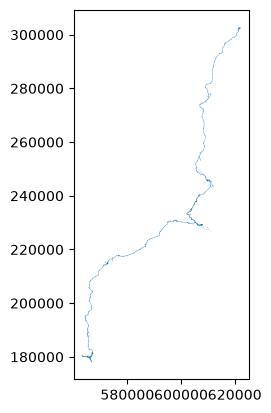

In [11]:
gdf_nt_route = gpd.read_file("../Routes/norwich-tilbury-boundary.geojson").to_crs("epsg:27700")
gdf_nt_route = gdf_nt_route.iloc[[2],:]
gdf_nt_route.plot()

D:\Profiles\Tim\AppData\Local\Temp\3\ipykernel_14232\1636816567.py:10: FutureWarning: You are adding a column named 'geometry' to a GeoDataFrame constructed without an active geometry column. Currently, this automatically sets the active geometry column to 'geometry' but in the future that will no longer happen. Instead, either provide geometry to the GeoDataFrame constructor (GeoDataFrame(... geometry=GeoSeries()) or use `set_geometry('geometry')` to explicitly set the active geometry column.
  gdf_buffer["geometry"] = buffer
D:\Profiles\Tim\AppData\Local\Temp\3\ipykernel_14232\1636816567.py:15: FutureWarning: You are adding a column named 'geometry' to a GeoDataFrame constructed without an active geometry column. Currently, this automatically sets the active geometry column to 'geometry' but in the future that will no longer happen. Instead, either provide geometry to the GeoDataFrame constructor (GeoDataFrame(... geometry=GeoSeries()) or use `set_geometry('geometry')` to explicitly 

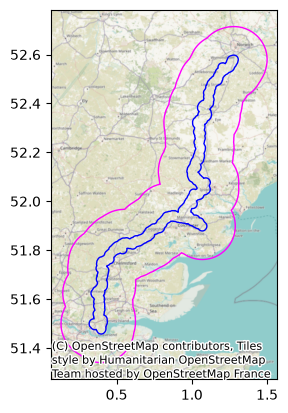

In [47]:
buffer = gdf_nt_route.buffer(15000)
buffer2 = gdf_nt_route.buffer(2000)

# The below is purely to get a look at the buffers.

bbox = box(*buffer.total_bounds)
bbox_4326 = box(*buffer.to_crs("epsg:4326").total_bounds)

gdf_buffer = gpd.GeoDataFrame()
gdf_buffer["geometry"] = buffer
gdf_buffer.set_crs("epsg:27700", inplace=True)
buffer = gdf_buffer["geometry"].union_all()

gdf_buffer2 = gpd.GeoDataFrame()
gdf_buffer2["geometry"] = buffer2
gdf_buffer2.set_crs("epsg:27700", inplace=True)
buffer2 = gdf_buffer2["geometry"].union_all()

gdf_buffer = pd.concat([gdf_buffer, gdf_buffer2], axis = 0)
del gdf_buffer2

fig, ax = plt.subplots()
gdf_buffer.to_crs("epsg:4326").iloc[[0]].plot(ax = ax, edgecolor = 'magenta', color = 'none')
gdf_buffer.to_crs("epsg:4326").iloc[[1]].plot(ax = ax, edgecolor = 'blue', color = 'none')
cx.add_basemap(ax = ax, crs = "epsg:4326", zoom = 9)



In [46]:
str(bbox)

'POLYGON ((637262.3343942686 162871.3347182794, 637262.3343942686 318030.20254252135, 547992.1189842399 318030.20254252135, 547992.1189842399 162871.3347182794, 637262.3343942686 162871.3347182794))'

In [40]:
gpd.list_layers("../../OSM data/Norwich-Tilbury OSM/norwich-tilbury.gpkg")
# The multilinestrings are all bus routes and similar and aren't needed.

,name,geometry_type
0,points,Point
1,lines,LineString
2,multilinestrings,MultiLineString
3,multipolygons,MultiPolygon
4,other_relations,GeometryCollection


In [64]:
gdf_osm_points = gpd.read_file("../../OSM data/Norwich-Tilbury OSM/norwich-tilbury.gpkg",
                               layer="points",
                               bbox=bbox_4326)
gdf_osm_points = gdf_osm_points.loc[gdf_osm_points["name"].map(bool)]
gdf_osm_points.sample(500)

gdf_osm_lines = gpd.read_file("../../OSM data/Norwich-Tilbury OSM/norwich-tilbury.gpkg",
                               layer="lines",
                               bbox=bbox_4326)
gdf_osm_lines = gdf_osm_lines.loc[gdf_osm_lines["name"].map(bool)]
gdf_osm_lines.sample(500)

gdf_osm_multipolygons = gpd.read_file("../../OSM data/Norwich-Tilbury OSM/norwich-tilbury.gpkg",
                               layer="multipolygons",
                               bbox=bbox_4326)
gdf_osm_multipolygons = gdf_osm_multipolygons.loc[gdf_osm_multipolygons["name"].map(bool)]
gdf_osm_multipolygons.sample(500)

,osm_id,osm_way_id,name,type,aeroway,amenity,admin_level,barrier,boundary,building,...,man_made,military,natural,office,place,shop,sport,tourism,other_tags,geometry
625,1551140,None,Tolleshunt D'Arcy,boundary,None,None,10,None,administrative,None,...,None,None,None,None,None,None,None,None,"""designation""=>""civil_parish"",""population""=>""1...","MULTIPOLYGON (((0.81272 51.7245, 0.81048 51.73..."
37640,None,90380619,Chestnut Avenue,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,"""highway""=>""residential"",""highway_authority_re...","MULTIPOLYGON (((1.3244 52.6931, 1.32457 52.693..."
255184,None,355353834,Gulpher Duck Pond,None,None,None,None,None,None,None,...,None,None,water,None,None,None,None,None,"""water""=>""pond""","MULTIPOLYGON (((1.35442 51.98156, 1.35467 51.9..."
107324,None,138576553,Willow Lodge,None,None,None,None,None,None,house,...,None,None,None,None,None,None,None,None,"""addr:city""=>""Colchester"",""addr:postcode""=>""CO...","MULTIPOLYGON (((0.93971 51.9216, 0.93968 51.92..."
420178,None,686892208,Ardmore,None,None,veterinary,None,None,None,yes,...,None,None,None,None,None,None,None,None,"""addr:city""=>""Great Yeldham"",""addr:housenumber...","MULTIPOLYGON (((0.56485 52.01653, 0.56494 52.0..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86492,None,122387267,Carter's Park,None,None,None,None,None,None,None,...,None,None,wood,None,None,None,None,None,"""source:name""=>""NLS - OS 6-inch County Series,...","MULTIPOLYGON (((0.56737 52.21199, 0.56741 52.2..."
163977,None,193865873,Blackwater Sailing Club,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,"""seamark:harbour:category""=>""marina"",""seamark:...","MULTIPOLYGON (((0.7146 51.73461, 0.71472 51.73..."
9069,None,39645690,Ipswich & District Bowling Club,None,None,None,None,None,None,yes,...,None,None,None,None,None,None,None,None,"""ref:GB:uprn""=>""100091506269""","MULTIPOLYGON (((1.19125 52.0627, 1.19183 52.06..."
72098,None,117397642,Comac Yard,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,"""addr:city""=>""Clacton-on-Sea"",""addr:postcode""=...","MULTIPOLYGON (((1.15027 51.80163, 1.15117 51.8..."


In [65]:
gdf_OSM = pd.concat([gdf_osm_points.loc[:,["name", "geometry"]],
                     gdf_osm_lines.loc[:,["name", "geometry"]],
                     gdf_osm_multipolygons.loc[:,["name", "geometry"]]], axis = 0)

gdf_OSM = gdf_OSM.to_crs("epsg:27700")

del gdf_osm_points, gdf_osm_lines, gdf_osm_multipolygons


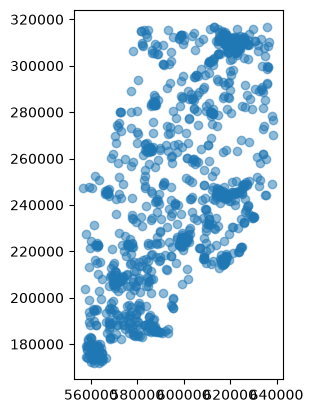

In [68]:
gdf_OSM["geometry"] = gdf_OSM["geometry"].centroid
gdf_OSM.sample(1000).plot(alpha = 0.5)
gdf_OSM["name_lower"] = gdf_OSM["name"].map(lambda s:s.lower())

(193408, 33)
(122145, 33)
(13648, 33)


<Axes: >

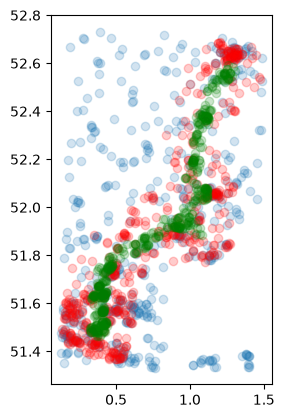

In [13]:
bbox_placenames = gpd.read_file(
    "../../OS Data/opname_gpkg_gb/Data/opname_gb.gpkg",
    bbox=bbox,
    # mask = buffer,
)
print(bbox_placenames.shape)

buffer1_placenames = gpd.read_file(
    "../../OS Data/opname_gpkg_gb/Data/opname_gb.gpkg",
    # bbox=bbox,
    mask = buffer,
)
print(buffer1_placenames.shape)

buffer2_placenames = gpd.read_file(
    "../../OS Data/opname_gpkg_gb/Data/opname_gb.gpkg",
    # bbox=bbox,
    mask = buffer2,
)
print(buffer2_placenames.shape)

fig, ax = plt.subplots()
bbox_placenames.sample(500).to_crs("epsg:4326").plot(ax = ax, alpha = 0.2)
buffer1_placenames.sample(500).to_crs("epsg:4326").plot(ax = ax, alpha = 0.2, color = 'red')
buffer2_placenames.sample(500).to_crs("epsg:4326").plot(ax = ax, alpha = 0.2, color = 'green')



In [14]:
bbox_placenames["name1_lower"] = bbox_placenames["name1"].map(lambda s:s.lower())
buffer1_placenames["name1_lower"] = buffer1_placenames["name1"].map(lambda s:s.lower())
buffer2_placenames["name1_lower"] = buffer2_placenames["name1"].map(lambda s:s.lower())
bbox_placenames.sample(100)

,id,names_uri,name1,name1_lang,name2,name2_lang,type,local_type,most_detail_view_res,least_detail_view_res,...,county_unitary_type,region,region_uri,country,country_uri,related_spatial_object,same_as_dbpedia,same_as_geonames,geometry,name1_lower
40276,RM109SL,http://data.ordnancesurvey.co.uk/id/postcodeun...,RM10 9SL,None,None,None,other,Postcode,3500,18000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,London,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (549641 184427),rm10 9sl
141679,osgb4000000029287653,http://data.ordnancesurvey.co.uk/id/4000000029...,St Andrews Road,None,None,None,transportNetwork,Named Road,1000,20000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (615149 278858),st andrews road
17515,osgb4000000073331742,http://data.ordnancesurvey.co.uk/id/4000000073...,Canterbury Christ Church University Broadstair...,None,None,None,other,Higher or University Education,1000,50000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,South East,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (637215 167769),canterbury christ church university broadstair...
43961,CM14PX,http://data.ordnancesurvey.co.uk/id/postcodeun...,CM1 4PX,None,None,None,other,Postcode,3500,18000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (561127 211222),cm1 4px
173844,CM98JL,http://data.ordnancesurvey.co.uk/id/postcodeun...,CM9 8JL,None,None,None,other,Postcode,3500,18000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (588903 211839),cm9 8jl
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79903,IP92LT,http://data.ordnancesurvey.co.uk/id/postcodeun...,IP9 2LT,None,None,None,other,Postcode,3500,18000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (612778 238190),ip9 2lt
173638,CM07QS,http://data.ordnancesurvey.co.uk/id/postcodeun...,CM0 7QS,None,None,None,other,Postcode,3500,18000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (600127 207471),cm0 7qs
143276,osgb4000000027466981,http://data.ordnancesurvey.co.uk/id/4000000027...,Ivory Road,None,None,None,transportNetwork,Named Road,1000,20000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,Eastern,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (620022 307810),ivory road
4951,DA125DR,http://data.ordnancesurvey.co.uk/id/postcodeun...,DA12 5DR,None,None,None,other,Postcode,3500,18000,...,http://data.ordnancesurvey.co.uk/ontology/admi...,South East,http://data.ordnancesurvey.co.uk/id/7000000000...,England,http://data.ordnancesurvey.co.uk/id/country/en...,None,None,None,POINT (565698 171594),da12 5dr


{'BEFUDDLEMENT',
 'WATERY',
 'RHEOMETER',
 'DEPOLARIZER',
 'PAVANS',
 'DESORPTIONS',
 'RECIPROCATE',
 'SCOWDERED',
 'AGGRANDISE',
 'METROPOLITAN',
 'DESOLATOR',
 'FLASHILY',
 'BUSKER',
 'PLAYROOM',
 'HENNAS',
 'MEDITATOR',
 'INANITIONS',
 'EMBARGO',
 'UNTHAWED',
 'BASIDIOMYCETES',
 'INCANTATION',
 'CONGESTING',
 'INFLICTORS',
 'JAMBE',
 'BICARBS',
 'GEOSCIENCES',
 'UNDERFED',
 'BLACKSMITHS',
 'CLIMB',
 'ASHLERING',
 'HOMOZYGOTE',
 'DARKENER',
 'INTRANASAL',
 'REIMPOSITIONS',
 'ZOCALOS',
 'MINNOWS',
 'LEAFWORMS',
 'HONOURER',
 'NULLITY',
 'MESOPHYLLOUS',
 'NOXIOUSLY',
 'CAST',
 'LICKING',
 'NUCELLUS',
 'FENNELS',
 'ARCUATELY',
 'CORRESPOND',
 'GHAZI',
 'HAMULATE',
 'SCREWBEANS',
 'MARATHONER',
 'BOGWOOD',
 'ADVOCACY',
 'LINTIEST',
 'NOWT',
 'CORKINESSES',
 'ANGORAS',
 'LIBERTINISM',
 'DELFTWARE',
 'SCUMMILY',
 'GLITTERINGLY',
 'BUDGETED',
 'TEARLESS',
 'FAGOTING',
 'EMBALMER',
 'ENCORED',
 'KOMONDOROK',
 'FARSEEING',
 'ADAPTIVELY',
 'JACQUARD',
 'WORKABLE',
 'ELAPINE',
 'HACIENDAS',
 'H

In [89]:
candidate_names_not_found = set()
candidate_names_not_found_OS = set()
found_multiple = set()

assert bbox_placenames.crs.name == 'OSGB36 / British National Grid'
assert bbox_placenames.crs.name == 'OSGB36 / British National Grid'
assert bbox_placenames.crs.name == 'OSGB36 / British National Grid'

gdf_located_places = gpd.GeoDataFrame(columns = ["place_name", "type", "local_type", "postcode_district", "populated_place", "county_unitary", "geometry", "approx_match_flag"])

def query_nominatim(candidate_name, adjusted_name):
    """Don't use. Better to download OSM data and use gpkg querying rather than this API."""
    locations = (geolocator.geocode(f"{adjusted_name}, Essex", exactly_one=False) or []) + (geolocator.geocode(f"{placename}, Suffolk", exactly_one=False) or []) + (geolocator.geocode(f"{placename}, norfolk", exactly_one=False) or [])

    time.sleep(1) # necessary to avoid infringing nominatim limits.

    results = gpd.GeoDataFrame(columns = ["geometry", "place_name", "type", "local_type",
                                          "postcode_district", "populated_place", "county_unitary"])
    if len(locations) > 0:
        results["geometry"] = gpd.points_from_xy([loc.longitude for loc in locations],[loc.latitude for loc in locations])
        # results["place_name"] = candidate_name
        # results["adjusted_name"] = adjusted_name
        results["type"] = None
        results["local_type"] = None
        results["postcode_district"] = None
        results["populated_place"] = None
        results["county_unitary"] = None
        results.set_crs("epsg:4326", inplace=True)

    return results

def look_for_possible_placename(candidate_name,
                                adjusted_name = None,
                                ):
    """
    Nominatim does not work well currently, and is also rate-limited.
    """
    # 'Adjusted name' refers to cases where we call this recursively, using only the first word of the phrase.

    found_where = None
    if not adjusted_name:
        original_name = True
        adjusted_name = candidate_name.strip()
    else:
        original_name = False

    # First look for the place using OS data:
    results = bbox_placenames.loc[bbox_placenames["name1_lower"] == adjusted_name.lower()]
    if results.shape[0] > 0:
        found_where = "OS"

    if (results.shape[0] == 0):
        # Try nominatim if nothing found from OS.
        # results = query_nominatim(candidate_name, adjusted_name)

        # Try the OSM gpkg instead:
        results = gdf_OSM.loc[gdf_OSM["name_lower"] == adjusted_name.lower()].copy()
        results["type"] = None
        results["local_type"] = None
        results["postcode_district"] = None
        results["populated_place"] = None
        results["county_unitary"] = None

        if results.shape[0] > 0:
            found_where = "OSM"

    if results.shape[0] == 0:
        if len(adjusted_name.strip().split(" ")) > 1:
            # If it's a multiple word string like 'Broomfield Library' we try our luck with just the first word to get an approx location.
            # We use recursion to do this.
            shortened_version = adjusted_name.strip().split(" ")[0]
            if shortened_version.upper() not in dictionary_words:
                return look_for_possible_placename(candidate_name, shortened_version)
            else:
                # This is an endpoint with failure to identify the placename.
                candidate_names_not_found.add(candidate_name)
                return False
        else:
            candidate_names_not_found.add(candidate_name)
            return False

    if results.shape[0] > 1:
        # If results are all nearby anyway, we can just accept the first result.
        total_bounds = results["geometry"].total_bounds
        if (abs(total_bounds[0] - total_bounds[2]) < 1000) and (abs(total_bounds[1] - total_bounds[3]) < 1000):
            results = results.iloc[[0]]

    if results.shape[0] > 1:
        # Try a tigher buffer (15km):
        results = results.loc[results["geometry"].intersects(buffer)]

    if results.shape[0] > 1:
        # Try a tigher buffer (2km):
        results = results.loc[results["geometry"].intersects(buffer2)]

    if results.shape[0] > 1:
        # Again, if results are all nearby anyway, we can just accept the first.
        total_bounds = results["geometry"].total_bounds
        if (abs(total_bounds[0] - total_bounds[2]) < 1000) and (abs(total_bounds[1] - total_bounds[3]) < 1000):
            results = results.iloc[[0]]

    # If we've managed to get one unique results then we've succeeded.
    if results.shape[0] == 1:
        results_ser = results.iloc[0]
        newind = gdf_located_places.shape[0]
        gdf_located_places.loc[newind, "place_name"] = candidate_name
        gdf_located_places.loc[newind, "adjusted_name"] = adjusted_name
        gdf_located_places.loc[newind, "found_where"] = found_where
        gdf_located_places.loc[newind, "type"] = results_ser["type"]
        gdf_located_places.loc[newind, "local_type"] = results_ser["local_type"]
        gdf_located_places.loc[newind, "postcode_district"] = results_ser["postcode_district"]
        gdf_located_places.loc[newind, "populated_place"] = results_ser["populated_place"]
        gdf_located_places.loc[newind, "county_unitary"] = results_ser["county_unitary"]
        gdf_located_places.loc[newind, "geometry"] = results_ser["geometry"]
        gdf_located_places.loc[newind, "approx_match_flag"] = (not original_name)
        return True
    else:
        # Means that multiple were found and we couldn't make a good guess at which was meant.
        # (of course a sophisticated method might look for clustering with other place names mentioned!)
        found_multiple.add(candidate_name)

for n,candidate_name in enumerate(list(unique_candidate_names)):
    print(n, end = ",")
    look_for_possible_placename(candidate_name)
    # if n > 50:
    #     break

gdf_located_places.to_file("N-T-located-places-v3.geojson", driver = "GeoJSON", crs = "epsg:27700")

# This should run at about 15 placenames per second.


0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207,208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,251,252,253,254,255,256,257,258,259,260,261,262,263,264,265,266,267,268,269,270,271,272,273,274,275,276,27

D:\Profiles\Tim\Documents\Community Response\Codebase\venv\Lib\site-packages\pyogrio\geopandas.py:948: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(


In [90]:
candidate_names_not_found

{'GH11',
 'Retreat Centre',
 'EU',
 'Mike Kent Honey',
 'Cost Benefit Analysis',
 'Covid',
 'Properly Consider',
 'ERF Secretariat',
 'Pre-Application Land',
 'HDV',
 'A3 Qualitative Groundwater Risk Assessment',
 'MASSIVE BONUS',
 'Long-standing',
 'ELECTRICALLY DRIVEN POWERED BY SOLAR ALONE',
 'IMPACT OF CONSTRUCTION',
 'GLH Equestrian',
 'Floodplain Interference',
 'Partridge Green Farm',
 'Government Ministers',
 'Pylons Campaign',
 'Helmand',
 'November',
 'Vantage RE',
 'OBJECTION TO ROUTE OF ELECTRICITY TRANSMISSION LINES INLAND NORWICH TO TILBURY',
 'Electrical Engineering',
 'Landscape Recovery',
 'Pitts',
 'PRINCIPAL SUBMISSIONS',
 'Consult Those Directly Affected',
 'Pylon Campaign',
 'PSC B1',
 'Surrounding Wildlife',
 'King John',
 'Fire Service Emergency Helicopters',
 'Policy Context',
 'ON THE ROUTE HANDED TO YOU AND',
 'Government Policy&#39',
 'Ignored Alternatives',
 'David Morrissey',
 'Flood Zones',
 'How NGET',
 'Offshore Integration',
 'Viable Alternatives Not Co

In [94]:
gdf_located_places = gdf_located_places.set_crs("epsg:27700")
gdf_located_places.to_file("N-T-located-places-v3.geojson", driver = "GeoJSON")

In [107]:
# Handling of places which have had words knocked off needs to be done carefully.
located_places_set = set(gdf_located_places["place_name"])

confirmed_places_dict = {id:[place for place in candidates if place in located_places_set] for id,candidates in candidate_places_dict.items()}

confirmed_places_dict = {id:list for id, list in confirmed_places_dict.items() if len(list) > 0}

with open("N-T-confirmed-place-dict.json", "w") as f:
    json.dump(confirmed_places_dict, f)

In [ ]:
# Upp Hall Farm
location = geolocator.geocode("Upp Hall Farm, Essex")
location





In [188]:
sorted(pd.Series(list(candidate_names_not_found)).sample(200))
# Concerned:
# Bellway, Boyton Hall, Broadview Farm, Broards Green
# Bushwood Farm, Buttevelyan, Chelmsford Rd, Chignal St, Colne River, Debden
# Wattisham Station, West Cottage, Took-Kirby, Tibernham, Thornham Parva

# Are some of the codes for pylons? Pylons are coded as RG__ or TB__ by the look of it. Possibly CM__

# Abby Bebbington, Acaster, Alborough House, Aldeburgh, Aldham Church, Altham, Ardleigh Conservation Area, Arnhem, Ash Tree Corner
# etc. etc.
# etc. etc.

# River Dove, River Yare.

['A1',
 'AECOM Writtle Design Guide',
 'APP-357',
 'Acquiring Authority',
 'Against Pylons',
 'Agricultural Show',
 'Alborough House',
 'Andrew Wilks',
 'Andy',
 'Anticipated Traffic Disruption',
 'Ashgreen Energyfarm Limited',
 'Associate Director',
 'Baker St',
 'Bamford',
 'Base Commander',
 'Between Fordham',
 'Bishops Hall Cottages',
 'Brettons Hall Farm',
 'British Standard',
 'CO2',
 'CSE',
 'Carters Meadow',
 'Christopher Owen',
 'Community Integrity',
 'Conservation Woodsman',
 'Consultation Fatigue Created',
 'Consultation Feedback',
 'Corke',
 'DCO Examination',
 'DONE DEAL',
 'DeepSeek',
 'Defective Environmental Assessment',
 'Dennis',
 'Design Change Request',
 'Direct Current',
 'Direct Negative Impact',
 'Disproportionate',
 'Distinctive Character',
 'Donald Campbell',
 'Dukes Farm',
 'E-1',
 'EFFECTS OF THE N2T PYLONS ON CHIGNAL PARISH',
 'EN0110019',
 'ESO East Anglia Network Study',
 'ESWMB',
 'EX531061',
 'EX915957',
 'Earl Stonham Parish Council OBJECTS STRONGLY',


In [96]:
len(found_multiple), found_multiple
# Tightening the search buffer reduced these from 275 to 149.
# Enabling reduction to one word massively increased it again to 5139.

(296,
 {'A10',
  'A1013 Stanford Road',
  'A1060',
  'A1071',
  'A11',
  'A1124',
  'A120',
  'A120 Coggeshall',
  'A127 Southend Arterial Road',
  'A128',
  'A130',
  'A131',
  'A134',
  'A137',
  'A14',
  'A140',
  'A2',
  'A2 Environmental Statement Appendix',
  'A414',
  'Acacia Road',
  'All Saints Church',
  'Angles Way',
  'Anglian Water',
  'Ardleigh Road',
  'B1018',
  'B1078',
  'B1113',
  'B1113 Finningham Road',
  'B1113 Walsham Road',
  'B1135',
  'B1508',
  'BP',
  'BP Oil UK Limited',
  'Bentley',
  'Bentley Road',
  'Bentley Road Widening',
  'Birchwood',
  'Birchwood Road',
  'Black Brook',
  'Boreham Road',
  'Boundary Farm',
  'Boxhouse Lane',
  'Boxted Road',
  'Braintree Road',
  'Breeds Road',
  'Brentwood',
  'Brentwood Borough Council',
  'Brentwood Borough Council&#39',
  'Brentwood Borough Councillor',
  'Brentwood Council',
  'Brentwood District',
  'Brentwood Local Plan',
  'Brentwood Road',
  'Brentwood Rural',
  'Brentwood Rural Division',
  'Brick Kiln La

In [183]:
gdf_located_places.sort_values("place_name")

# And of course some places are mentioned multiple times, so we have more than 262 data items here to work with.

# Using just OS named places, we identified 262 places mentioned in our representations (without attachments).
# By filtering down multiple matches by accepting the ones in the tigher bufferzones, increased this to 316.
# By also accepting multiple matches that are within 1000mx1000m, increased further to 391.

# Enabling locations to be goelocated using just the first word increased this to 775.

# Lookup pylons as RG__ or TB__ or pylon RG__, pylon TB__ will also be of use.
# It appears that obtaining these as gpkg or geojson is impractical...unless can make aggressive use of AI to get it done.

# Lookups using nominatim, should increase this further.




,place_name,type,local_type,postcode_district,populated_place,county_unitary,geometry,approx_match_flag
394,A1066,transportNetwork,Section Of Numbered Road,IP22,Diss,Norfolk,POINT (612027 279539),False
99,A1089,transportNetwork,Numbered Road,RM17,None,Thurrock,POINT (563424 178084),False
647,A1120,transportNetwork,Section Of Numbered Road,IP14,None,Suffolk,POINT (606133 257556),False
358,A12,transportNetwork,Numbered Road,CO4,None,Essex,POINT (598938 228951),False
608,A12 Marks Tey,transportNetwork,Numbered Road,CO4,None,Essex,POINT (598938 228951),True
...,...,...,...,...,...,...,...,...
677,Writtle Village Design Statement,populatedPlace,Village,CM1,None,Essex,POINT (567859 206288),True
417,Wymondham,transportNetwork,Railway Station,NR18,Wymondham,Norfolk,POINT (611417 300970),False
339,Wymondham Road,transportNetwork,Section Of Named Road,NR16,Wreningham,Norfolk,POINT (615442 298681),False
27,Yaxley,populatedPlace,Village,IP23,None,Suffolk,POINT (612007 273828),False


<Axes: >

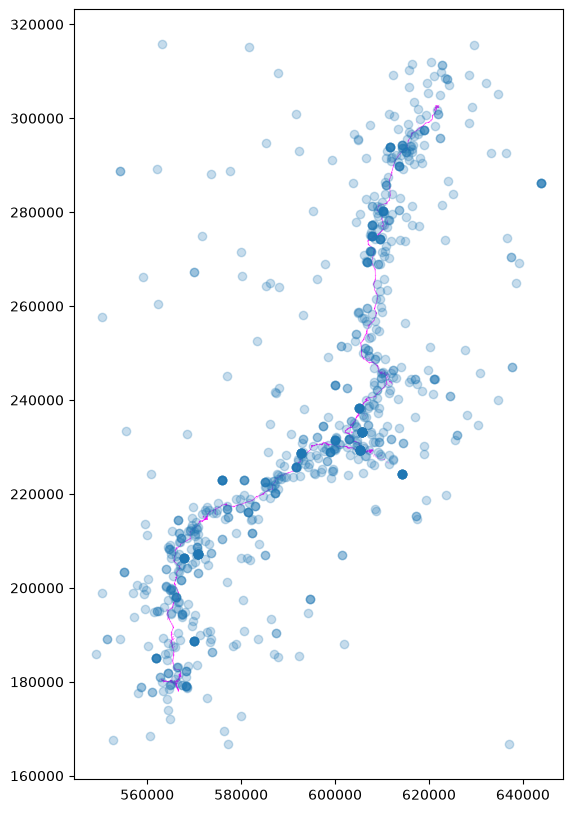

In [97]:
fig, ax = plt.subplots(figsize = (10, 10))
gdf_nt_route.plot(ax = ax, color = "magenta")
gdf_located_places.plot(ax = ax, alpha = 0.25)

In [ ]:
# Where the first word of a multiword phrase is matchable, it should go down as an additional match for that place. (Though ultimately we will only count one mention per representation.) => This is now done, and doubled the amount of places we succeeded in locating.

# There is the option to locate the pylons that are mentioned. However, the locations of these pylons don't seem to have been published in an easily readable form.

# We might need to check for letters that have been copied and pasted as these do not necessarily represent genuine concern about all the places mentioned.

In [106]:
confirmed_places_dict

{'100008573': [],
 '100008574': [],
 '100008577': [],
 '100008579': ['Dedham', 'Tendring', 'Ardleigh'],
 '100008581': ['A12',
  'Ardleigh',
  'Tendring',
  'Home Farm Lane',
  'Ardleigh Parish Council'],
 '100008583': [],
 '100008584': [],
 '100008586': [],
 '100008590': [],
 '100008592': ['Billericay', 'Hutton'],
 '100008595': [],
 '100008598': ['Mellis',
  'Gislingham',
  'Burgate Wood',
  'Mellis Common',
  'Wortham'],
 '100008599': [],
 '100008601': ['Waveney Valley', 'Wortham'],
 '100008602': [],
 '100008603': ['Buttsbury Lane', 'Ingatestone'],
 '100008607': [],
 '100008609': [],
 '100008611': ['Wortham Church', 'Wortham Ling', 'Wortham'],
 '100008612': ['Chattisham'],
 '100008613': ['Chelmsford Garden Community'],
 '100008615': [],
 '100008616': [],
 '100008617': [],
 '100008619': ['Bramford',
  'Bradwell-on-Sea',
  'Roydon Fen',
  'Waveney Valley',
  'Wortham Ling',
  'Redgrave',
  'Waveney Valley Alternative&#39',
  'Bressingham',
  'Rayleigh'],
 '100008620': [],
 '100008621': 

In [111]:
[v for v in confirmed_places_dict.values() if "Rams Farm Road" in v]

[['Aldham',
  'River Colne',
  'Fordham',
  'Woodland Trust',
  'Fordham Local History Society',
  'Rams Farm Road',
  'Babergh',
  'Hillhouse Wood',
  'Aldham TB48',
  'Fossetts Lane',
  'West Bergholt',
  'Fordham Village',
  'Colne',
  'Fordham Hall Estate']]

In [161]:
gdf_representations = pd.DataFrame(index = confirmed_places_dict.keys())

for rep, placelist in confirmed_places_dict.items():
    tempdf = gdf_located_places.loc[gdf_located_places["place_name"].isin(placelist)]
    geom = tempdf["geometry"].union_all() # all geographies were reduced to points so this should work OK.

    gdf_representations.loc[rep, "all_located_points"] = geom
    # gdf_representations.at[rep, "all_located_placenames"] =

gdf_representations["geometry"] = gdf_representations["all_located_points"]
gdf_representations["enumeration"] = range(gdf_representations.shape[0])

gdf_representations = gpd.GeoDataFrame(gdf_representations, geometry = "geometry")
gdf_representations["centroid"] = gdf_representations["geometry"].centroid
gdf_representations["bounding_box"] = gdf_representations["geometry"].convex_hull


In [162]:
def get_spider(pt, multipt):
    if type(multipt) == shapely.MultiPoint:
        return shapely.MultiLineString([LineString([pt, p]) for p in multipt.geoms])
    else:
        return pt

gdf_representations["spider"] = gdf_representations.apply(lambda gdf:get_spider(gdf["centroid"],gdf["all_located_points"]), axis = 1)

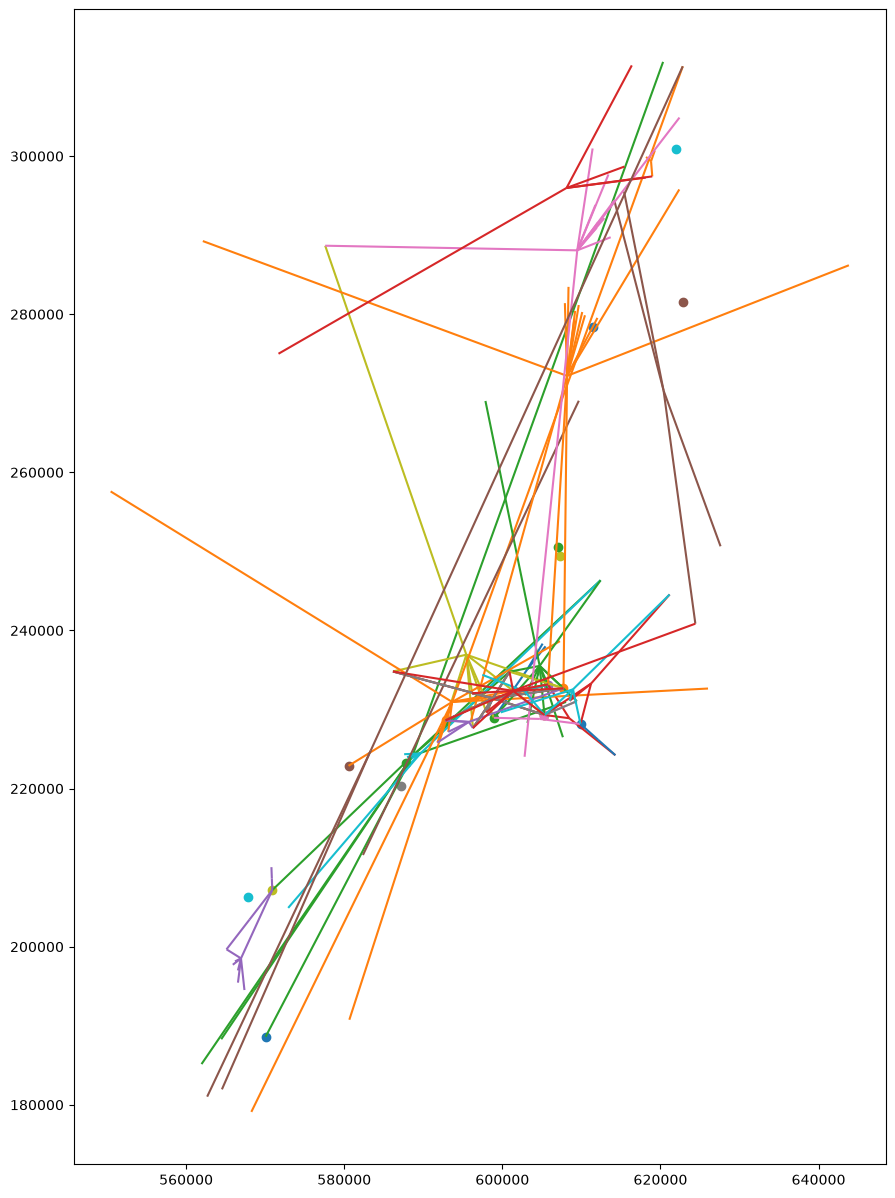

In [163]:
# 1421 representations have been identified with mentioned placenames.
colour_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']

fig, ax = plt.subplots(figsize = (15,15))
gdf_representations = gdf_representations.set_geometry("spider")
n = 0
for ind in gdf_representations.sample(50).index:
    colour =colour_cycle[n % len(colour_cycle)]
    gdf_representations.loc[[ind]].plot(ax = ax, color = colour)
    n+=1

In [168]:
gdf_representations.to_csv("gdf_representations.csv")

In [5]:
gdf_representations = pd.read_csv("gdf_representations.csv")

<Axes: >

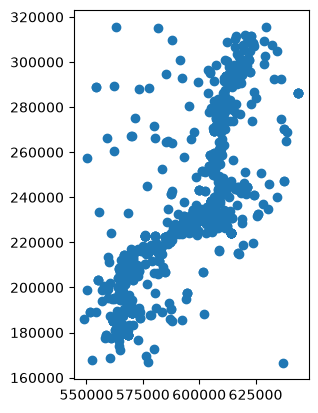

In [6]:
gdf_located_places = gpd.read_file("N-T-located-places-v3.geojson")
gdf_located_places.plot()

In [7]:
with open("N-T-confirmed-place-dict.json", "r") as f:
    confirmed_places_dict = json.load(f)
confirmed_places_dict

{'100008579': ['Dedham', 'Tendring', 'Ardleigh'],
 '100008581': ['A12',
  'Ardleigh',
  'Tendring',
  'Home Farm Lane',
  'Ardleigh Parish Council'],
 '100008592': ['Billericay', 'Hutton'],
 '100008598': ['Mellis',
  'Gislingham',
  'Burgate Wood',
  'Mellis Common',
  'Wortham'],
 '100008601': ['Waveney Valley', 'Wortham'],
 '100008603': ['Buttsbury Lane', 'Ingatestone'],
 '100008611': ['Wortham Church', 'Wortham Ling', 'Wortham'],
 '100008612': ['Chattisham'],
 '100008613': ['Chelmsford Garden Community'],
 '100008619': ['Bramford',
  'Bradwell-on-Sea',
  'Roydon Fen',
  'Waveney Valley',
  'Wortham Ling',
  'Redgrave',
  'Waveney Valley Alternative&#39',
  'Bressingham',
  'Rayleigh'],
 '100008625': ['Ardleigh'],
 '100008628': ['Offton'],
 '100008631': ['Bradwell'],
 '100008635': ['Stoke Ash',
  'Coldham Lane',
  'Gislingham',
  'Burgate Rd',
  'Hartismere High School',
  'Conservation Area',
  'Roydon',
  'Thornham Magna',
  'Finningham',
  'Back Street',
  'Mellis Primary',
  'Bur

In [9]:
df_mention_array = pd.DataFrame(index = confirmed_places_dict.keys(),
                                columns = list(gdf_located_places["place_name"]))

for rep, list in confirmed_places_dict.items():
    df_mention_array.loc[rep, list] = 1

df_mention_array


,Stowupland,Horsley Cross,Aldham Colchester,Galleywood Rd,Ringshall,Chelmsford Rd,Shelfanger,Fryerning Parish Council,Gislingham Parish,Long Stratton Road,...,Silver End,Waveney Valley,Winfarthing Pendant,Willisham,Great Bromley,Harts Lane,Thurrock Council&#39,Higham Village,Peake Fruit,ONGAR HALL FARM
100008579,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100008581,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100008592,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100008598,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100008601,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100023362,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100023400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100023428,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100023429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
place_mention_ranking = df_mention_array.sum(axis = 0)
place_mention_ranking

Stowupland              4
Horsley Cross           2
Aldham Colchester       1
Galleywood Rd           1
Ringshall               1
                       ..
Harts Lane              2
Thurrock Council&#39    1
Higham Village          3
Peake Fruit             1
ONGAR HALL FARM         1
Length: 927, dtype: object